**Tópicos Selectos en Aprendizaje Maquinal - TP N°1: Algoritmos para Reconocimiento de Patrones**

**Estanislao Claucich**

### Ejercicio 2: Clasificación estadística de patrones

1. Sea un clasificador geométrico lineal definido por: $g_1(\mathbf{x})=-x_1$, $g_2(\mathbf{x})=x_1+x_2-1$, $g_3(\mathbf{x})=x_1-x_2-1$.  
    a) Calcule y grafique las fronteras y regiones de decisión.  
    b) Clasifique los puntos: $(2,1)$; $(2,-1)$; $(-1,1)$; $(-1,-1)$.

2. Sean $A$ y $B$ dos clases de igual probabilidad a priori definidas por: $P(\mathbf{x}|A)\sim\mathcal{N}\!\left(\begin{pmatrix}3\\0\end{pmatrix},\mathbf{I}\right)$ y $P(\mathbf{x}|B)\sim\mathcal{N}\!\left(\begin{pmatrix}0\\3\end{pmatrix},\mathbf{I}\right)$.  
    a) Construya un clasificador gaussiano y encuentre la frontera.  
    b) Realice una representación gráfica del problema.

3. Implemente un clasificador gaussiano por ML para el mini-corpus de muestras proporcionado, realizando una representación gráfica de la situación:  
    a) Clasifique los datos del conjunto de entrenamiento y calcule la tasa de aciertos.  
    b) A partir de los parámetros obtenidos genere nuevos datos de prueba, clasifíquelos y compare con el resultado anterior.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

Un clasificador de $C$ clases se describe con funciones $g_1(\mathbf{x}),\dots,g_C(\mathbf{x})$ y la regla

$$
\mathbf{x}\in\mathcal{R}_i \quad\Longleftrightarrow\quad g_i(\mathbf{x})>g_j(\mathbf{x})\ \ \forall j\neq i .
$$

La frontera entre las clases $i$ y $j$ es el conjunto donde $g_i(\mathbf{x})=g_j(\mathbf{x})$. Los puntos se clasifican evaluando todos los $g_i$ y eligiendo el máximo.

### 1. Clasificador geométrico lineal

**a) Fronteras:** Igualando los discriminantes de a pares:

$$
\begin{aligned}
g_1=g_2:&\quad -x_1=x_1+x_2-1 \;\Rightarrow\; 2x_1+x_2=1,\\
g_1=g_3:&\quad -x_1=x_1-x_2-1 \;\Rightarrow\; 2x_1-x_2=1,\\
g_2=g_3:&\quad x_1+x_2-1=x_1-x_2-1 \;\Rightarrow\; x_2=0.
\end{aligned}
$$

Las tres rectas se cortan en $(0.5,\,0)$. De cada recta solo forma parte de la frontera la semirrecta donde ese empate es el máximo de los tres discriminantes: $g_1=g_2$ para $x_1\le0.5$ (arriba), $g_1=g_3$ para $x_1\le0.5$ (abajo) y $g_2=g_3$ para $x_1\ge0.5$. Las regiones quedan: $\mathcal{R}_1$ a la izquierda, $\mathcal{R}_2$ arriba a la derecha y $\mathcal{R}_3$ abajo a la derecha.

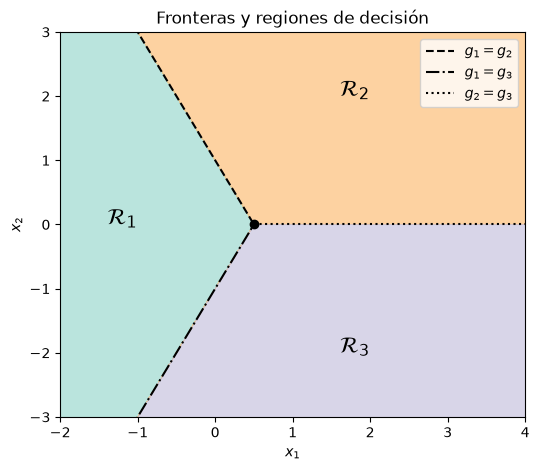

In [ ]:
# g_i(x) = w_i . x + b_i
W = np.array([[-1, 0], [1, 1], [1, -1]], dtype=float)
b = np.array([0, -1, -1], dtype=float)

def clasificar_lineal(X):
    return np.argmax(X @ W.T + b, axis=1) + 1

# Regiones de decisión
xx, yy = np.meshgrid(np.linspace(-2, 4, 500), np.linspace(-3, 3, 500))
regiones = clasificar_lineal(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6, 5))
ax.contourf(xx, yy, regiones, levels=[0.5, 1.5, 2.5, 3.5], colors=["#8dd3c7", "#fdb462", "#bebada"], alpha=0.6)

x1a = np.linspace(-2, 0.5, 50); x1b = np.linspace(0.5, 4, 50)
ax.plot(x1a, 1 - 2*x1a, "k--", label="$g_1=g_2$")
ax.plot(x1a, 2*x1a - 1, "k-.", label="$g_1=g_3$")
ax.plot(x1b, 0*x1b, "k:", label="$g_2=g_3$")
ax.plot(0.5, 0, "ko")

for txt, pos in zip(["$\\mathcal{R}_1$", "$\\mathcal{R}_2$", "$\\mathcal{R}_3$"], [(-1.2, 0), (1.8, 2), (1.8, -2)]):
    ax.text(*pos, txt, fontsize=16, ha="center")
ax.set(xlim=(-2, 4), ylim=(-3, 3), xlabel="$x_1$", ylabel="$x_2$", title="Fronteras y regiones de decisión")
ax.legend(loc="upper right")
plt.show()

**b)** Se evalúan los tres discriminantes en cada punto y se toma el máximo.

  punto   |  g1  g2  g3 | clase
( 2, 1)  |  -2   2   0 |   2
( 2,-1)  |  -2   0   2 |   3
(-1, 1)  |   1  -1  -3 |   1
(-1,-1)  |   1  -3  -1 |   1


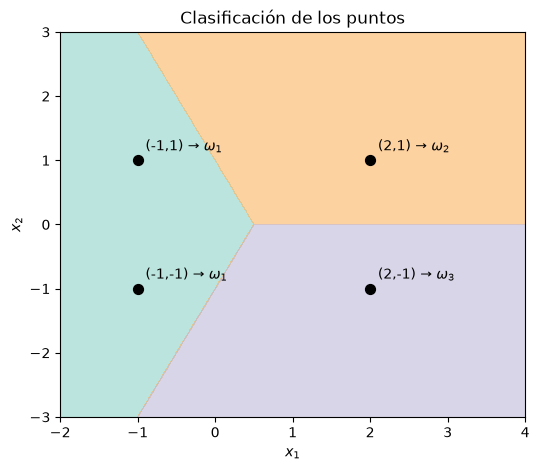

In [4]:
puntos = np.array([[2, 1], [2, -1], [-1, 1], [-1, -1]], dtype=float)
G = puntos @ W.T + b

print("  punto   |  g1  g2  g3 | clase")
for p, g, c in zip(puntos, G, clasificar_lineal(puntos)):
    print(f"({p[0]:2.0f},{p[1]:2.0f})  | {g[0]:3.0f} {g[1]:3.0f} {g[2]:3.0f} |   {c}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.contourf(xx, yy, regiones, levels=[0.5, 1.5, 2.5, 3.5], colors=["#8dd3c7", "#fdb462", "#bebada"], alpha=0.6)
ax.scatter(*puntos.T, c="k", s=50)
for p, c in zip(puntos, clasificar_lineal(puntos)):
    ax.annotate(f"({p[0]:.0f},{p[1]:.0f}) → $\\omega_{c}$", p, xytext=(p[0] + 0.1, p[1] + 0.15))
ax.set(xlim=(-2, 4), ylim=(-3, 3), xlabel="$x_1$", ylabel="$x_2$", title="Clasificación de los puntos")
plt.show()

*Los puntos con $x_1=-1$ caen en la región $\mathcal{R}_1$; los dos con $x_1=2$ quedan separados por la recta $x_2=0$: $(2,1)$ en $\mathcal{R}_2$ y $(2,-1)$ en $\mathcal{R}_3$.*

### 2. Clasificador gaussiano de dos clases

La regla de mínimo error asigna $\mathbf{x}$ a la clase con mayor probabilidad a posteriori $P(\omega_i|\mathbf{x})\propto p(\mathbf{x}|\omega_i)P(\omega_i)$. Tomando logaritmos, con verosimilitudes $\mathcal{N}(\boldsymbol{\mu}_i,\boldsymbol{\Sigma}_i)$, los discriminantes son

$$
g_i(\mathbf{x})=-\tfrac12(\mathbf{x}-\boldsymbol{\mu}_i)^\top\boldsymbol{\Sigma}_i^{-1}(\mathbf{x}-\boldsymbol{\mu}_i)-\tfrac12\ln|\boldsymbol{\Sigma}_i|+\ln P(\omega_i).
$$

**a)** Con $\boldsymbol{\Sigma}_A=\boldsymbol{\Sigma}_B=\mathbf{I}$ y $P(A)=P(B)=\tfrac12$, los términos $\ln|\boldsymbol{\Sigma}|$ y $\ln P$ se cancelan y la frontera $g_A=g_B$ queda

$$
-\tfrac12\|\mathbf{x}-\boldsymbol{\mu}_A\|^2+\tfrac12\|\mathbf{x}-\boldsymbol{\mu}_B\|^2=0
\;\Rightarrow\;
(\boldsymbol{\mu}_A-\boldsymbol{\mu}_B)^\top\mathbf{x}=\tfrac12\left(\|\boldsymbol{\mu}_A\|^2-\|\boldsymbol{\mu}_B\|^2\right).
$$

Con $\boldsymbol{\mu}_A=(3,0)^\top$ y $\boldsymbol{\mu}_B=(0,3)^\top$: $\ 3x_1-3x_2=\tfrac12(9-9)=0$, es decir,

$$
x_1=x_2
$$

Es una recta (la mediatriz entre las dos medias), se decide $A$ si $x_1>x_2$ y $B$ si $x_1<x_2$. Es lo esperable, con covarianzas iguales a $\mathbf{I}$ y priors iguales, cada punto se asigna a la media más cercana.

In [8]:
def discriminantes(X, mus, Sigmas, priors):
    G = []
    for mu, S, P in zip(mus, Sigmas, priors):
        d = X - mu
        mahal2 = np.einsum("nj,jk,nk->n", d, np.linalg.inv(S), d)
        G.append(-0.5 * mahal2 - 0.5 * np.linalg.slogdet(S)[1] + np.log(P))
    return np.array(G).T

def clasificar_gauss(X, mus, Sigmas, priors):
    return np.argmax(discriminantes(X, mus, Sigmas, priors), axis=1)


def elipse(mu, Sigma, k, n=200):
    lam, V = np.linalg.eigh(Sigma)
    t = np.linspace(0, 2*np.pi, n)
    return (mu[:, None] + k * V @ (np.sqrt(lam)[:, None] * np.vstack([np.cos(t), np.sin(t)]))).T


def muestrear(mus, Sigmas, priors, N, rng):
    y = rng.choice(len(mus), size=N, p=priors)
    X = np.array([rng.multivariate_normal(mus[i], Sigmas[i]) for i in y])
    return X, y

**b)** Se generan muestras de cada clase y se grafican junto con las curvas de nivel ($1\sigma$, $2\sigma$, $3\sigma$), la frontera $x_1=x_2$ y las regiones que produce el clasificador implementado.

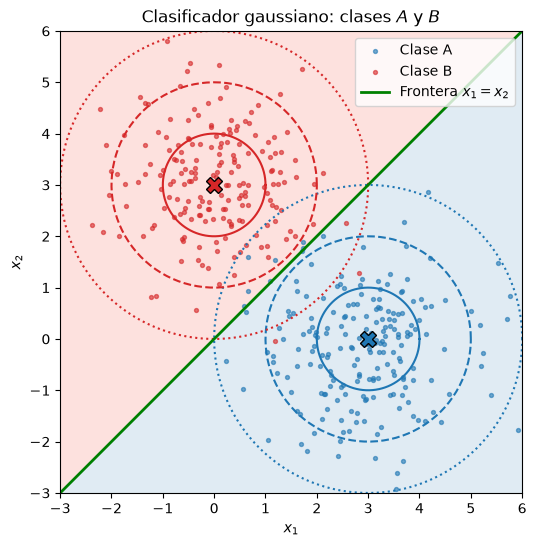

Errores sobre las 400 muestras: 11  (2.75%)


In [7]:
mus_AB = [np.array([3.0, 0.0]), np.array([0.0, 3.0])]
Sigmas_AB = [np.eye(2), np.eye(2)]
priors_AB = [0.5, 0.5]

X_AB, y_AB = muestrear(mus_AB, Sigmas_AB, priors_AB, 400, rng)
y_hat = clasificar_gauss(X_AB, mus_AB, Sigmas_AB, priors_AB)

xx2, yy2 = np.meshgrid(np.linspace(-3, 6, 400), np.linspace(-3, 6, 400))
reg = clasificar_gauss(np.c_[xx2.ravel(), yy2.ravel()], mus_AB, Sigmas_AB, priors_AB).reshape(xx2.shape)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.contourf(xx2, yy2, reg, levels=[-0.5, 0.5, 1.5], colors=["#b3cde3", "#fbb4ae"], alpha=0.4)
for i, (nombre, c) in enumerate([("A", "tab:blue"), ("B", "tab:red")]):
    ax.scatter(*X_AB[y_AB == i].T, s=8, color=c, alpha=0.6, label=f"Clase {nombre}")
    for k, ls in zip([1, 2, 3], ["-", "--", ":"]):
        e = elipse(mus_AB[i], Sigmas_AB[i], k); ax.plot(e[:, 0], e[:, 1], color=c, ls=ls)
    ax.plot(*mus_AB[i], "X", color=c, ms=11, mec="k")
ax.plot([-3, 6], [-3, 6], "g-", lw=2, label="Frontera $x_1=x_2$")
ax.set(xlim=(-3, 6), ylim=(-3, 6), xlabel="$x_1$", ylabel="$x_2$", aspect="equal",
       title="Clasificador gaussiano: clases $A$ y $B$")
ax.legend(loc="upper right")
plt.show()

print(f"Errores sobre las 400 muestras: {np.sum(y_hat != y_AB)}  ({np.mean(y_hat != y_AB)*100:.2f}%)")

### 3. Clasificador gaussiano por máxima verosimilitud

Cuando los parámetros no se conocen se estiman a partir de los datos. Con $n_i$ muestras $\mathbf{x}_k$ de la clase $\omega_i$ y $N$ en total, los estimadores de máxima verosimilitud son

$$
\hat{\boldsymbol{\mu}}_i=\frac{1}{n_i}\sum_{k\in\omega_i}\mathbf{x}_k,\qquad
\hat{\boldsymbol{\Sigma}}_i=\frac{1}{n_i}\sum_{k\in\omega_i}(\mathbf{x}_k-\hat{\boldsymbol{\mu}}_i)(\mathbf{x}_k-\hat{\boldsymbol{\mu}}_i)^\top,\qquad
\hat P(\omega_i)=\frac{n_i}{N}.
$$

Con estos parámetros se usan los mismos discriminantes $g_i(\mathbf{x})$ anteriores, con una covarianza distinta por clase (fronteras cuadráticas).

In [9]:
datos = np.loadtxt("gaussDATA.txt")
X, y = datos[:, :2], datos[:, 2].astype(int)
clases = np.unique(y)
y = np.searchsorted(clases, y)

# Estimación ML
mus = [X[y == i].mean(axis=0) for i in range(len(clases))]
Sigmas = [np.cov(X[y == i].T, ddof=0) for i in range(len(clases))]
priors = [np.mean(y == i) for i in range(len(clases))]

print(f"{len(X)} muestras, {len(clases)} clases")
for i, c in enumerate(clases):
    print(f"Clase {c}: n = {np.sum(y == i):2d}  P = {priors[i]:.3f}  mu = {mus[i].round(2)}  Sigma = {Sigmas[i].round(2).tolist()}")

69 muestras, 4 clases
Clase 1: n = 15  P = 0.217  mu = [1. 1.]  Sigma = [[1.0, 0.59], [0.59, 0.92]]
Clase 2: n = 13  P = 0.188  mu = [2. 4.]  Sigma = [[0.71, -0.6], [-0.6, 1.96]]
Clase 3: n = 18  P = 0.261  mu = [ 3. -1.]  Sigma = [[2.0, -1.01], [-1.01, 0.9]]
Clase 4: n = 23  P = 0.333  mu = [5. 2.]  Sigma = [[3.98, 0.1], [0.1, 0.38]]


**a) Clasificación del conjunto de entrenamiento:** La tasa de aciertos es la fracción de muestras bien clasificadas.

Tasa de aciertos (entrenamiento): 88.4%  (61/69)


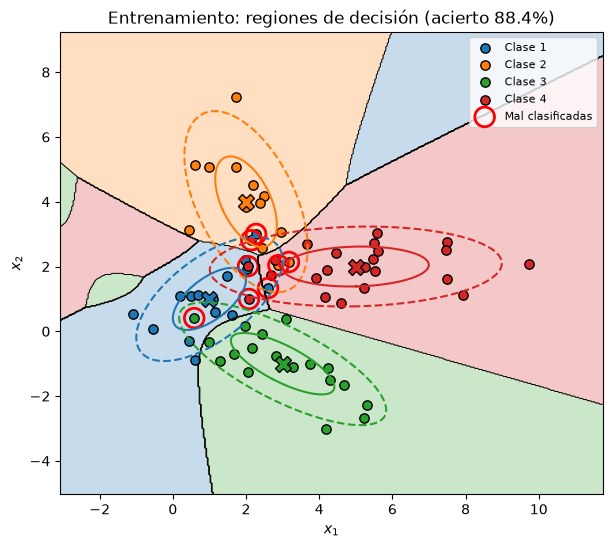

In [10]:
y_pred = clasificar_gauss(X, mus, Sigmas, priors)
acc_train = np.mean(y_pred == y)
print(f"Tasa de aciertos (entrenamiento): {acc_train*100:.1f}%  ({np.sum(y_pred == y)}/{len(y)})")

colores = plt.cm.tab10(np.arange(len(clases)))
xlim3 = (X[:, 0].min() - 2, X[:, 0].max() + 2); ylim3 = (X[:, 1].min() - 2, X[:, 1].max() + 2)
xx3, yy3 = np.meshgrid(np.linspace(*xlim3, 400), np.linspace(*ylim3, 400))
reg3 = clasificar_gauss(np.c_[xx3.ravel(), yy3.ravel()], mus, Sigmas, priors).reshape(xx3.shape)
niveles = np.arange(len(clases) + 1) - 0.5


def graficar_regiones(ax):
    ax.contourf(xx3, yy3, reg3, levels=niveles, colors=colores[:len(clases)], alpha=0.25)
    ax.contour(xx3, yy3, reg3, levels=niveles, colors="k", linewidths=0.7)
    ax.set(xlim=xlim3, ylim=ylim3, xlabel="$x_1$", ylabel="$x_2$")


fig, ax = plt.subplots(figsize=(7, 6))
graficar_regiones(ax)
for i, c in enumerate(clases):
    ax.scatter(*X[y == i].T, color=colores[i], edgecolor="k", s=45, label=f"Clase {c}")
    for k, ls in zip([1, 2], ["-", "--"]):
        e = elipse(mus[i], Sigmas[i], k); ax.plot(e[:, 0], e[:, 1], color=colores[i], ls=ls)
    ax.plot(*mus[i], "X", color=colores[i], ms=12, mec="k")
ax.scatter(*X[y_pred != y].T, s=200, facecolors="none", edgecolors="red", linewidths=2, label="Mal clasificadas")
ax.set_title(f"Entrenamiento: regiones de decisión (acierto {acc_train*100:.1f}%)")
ax.legend(loc="upper right", fontsize=8)
plt.show()

**b)** Datos de prueba generados con los parámetros estimados.

Entrenamiento (N = 69):                 88.4%
Prueba sintética (N = 100000):           86.9%
Pruebas sintéticas de N = 69 (x1000):   87.0% ± 4.1%


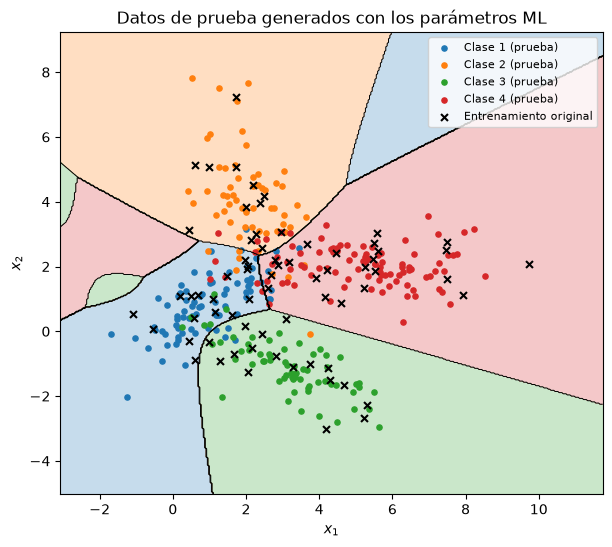

In [11]:
X_test, y_test = muestrear(mus, Sigmas, priors, 100000, rng)
acc_test = np.mean(clasificar_gauss(X_test, mus, Sigmas, priors) == y_test)

acc_chicos = []
for _ in range(1000):
    Xs, ys = muestrear(mus, Sigmas, priors, len(X), rng)
    acc_chicos.append(np.mean(clasificar_gauss(Xs, mus, Sigmas, priors) == ys))

print(f"Entrenamiento (N = {len(X)}):                 {acc_train*100:.1f}%")
print(f"Prueba sintética (N = 100000):           {acc_test*100:.1f}%")
print(f"Pruebas sintéticas de N = {len(X)} (x1000):   {np.mean(acc_chicos)*100:.1f}% ± {np.std(acc_chicos)*100:.1f}%")


Xp, yp = muestrear(mus, Sigmas, priors, 300, rng)
fig, ax = plt.subplots(figsize=(7, 6))
graficar_regiones(ax)
for i, c in enumerate(clases):
    ax.scatter(*Xp[yp == i].T, color=colores[i], s=14, label=f"Clase {c} (prueba)")
ax.scatter(*X.T, c="k", marker="x", s=25, label="Entrenamiento original")
ax.set_title("Datos de prueba generados con los parámetros ML")
ax.legend(loc="upper right", fontsize=8)
plt.show()

*La tasa de aciertos sobre datos nuevos coincide con la del entrenamiento dentro de la variabilidad esperable, con solo 69 muestras la diferencia observada no es significativa. Los errores se concentran donde las elipses de las clases se solapan.*

### Conclusiones

1. **Clasificador lineal:** Las fronteras son las rectas $g_i=g_j$ y las regiones son cuñas que concurren en $(0.5,\,0)$. Los puntos $(2,1)$, $(2,-1)$, $(-1,1)$ y $(-1,-1)$ pertenecen a $\omega_2$, $\omega_3$, $\omega_1$ y $\omega_1$, respectivamente.
2. **Clasificador gaussiano de Bayes:** Con covarianzas iguales a $\mathbf{I}$ y priors iguales, la frontera es la recta $x_1=x_2$ (mediatriz de las medias) y el clasificador equivale a asignar cada punto a la media más cercana.
3. **Clasificador gaussiano por ML:** Los parámetros de cada clase ($\hat{\boldsymbol{\mu}}_i$, $\hat{\boldsymbol{\Sigma}}_i$, $\hat P(\omega_i)$) se estiman directamente de los datos; con una covarianza por clase las fronteras son curvas.